<a href="https://colab.research.google.com/github/gerardowarbringer-eng/Programacion-para-Analitica-Descrip-Predict/blob/main/PracticaRegresionLinealMultiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: GERARDO ISIDORO REYES
*   Matrícula:271770

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [254]:

# Importar bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

In [255]:
# Lectura del conjunto de Datos
df =pd.read_csv('drive/MyDrive/Unidad03/advertising.csv')

#I nformación general
print('Información general del conjunto de datos\n')
print(df.info())

# Muestra las primeras filas del dataframe
print("Primeras filas DF:")
display(df.head())

# Describe estadísticamente las variables
print("Descripción estadística de las variables:")
display(df.describe())



Información general del conjunto de datos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB
None
Primeras filas DF:


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


Descripción estadística de las variables:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [256]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

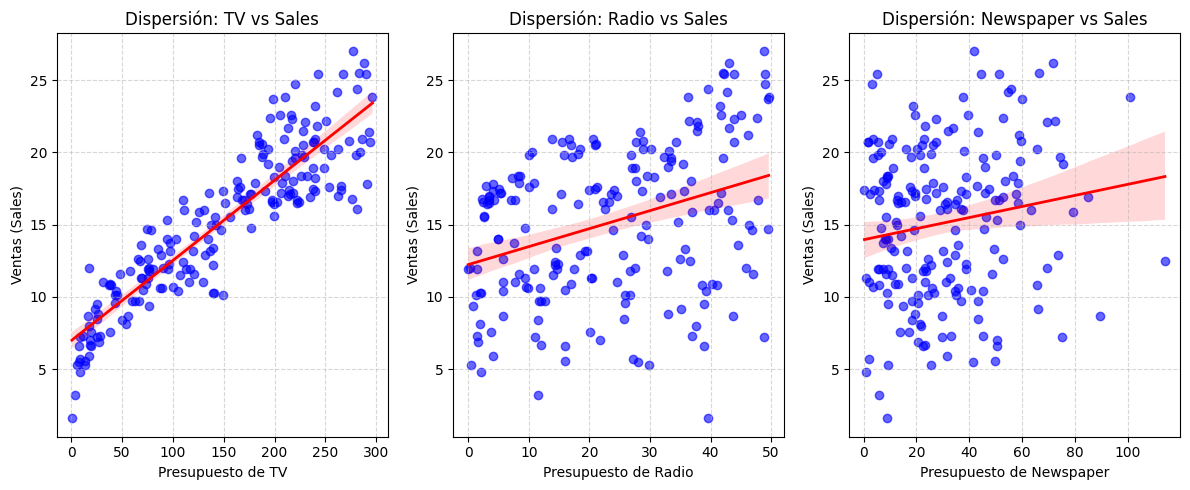

In [257]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

# Variables independientes a graficar
features = ['TV', 'Radio', 'Newspaper']

# Gráfica de dispersión
for ax, feature in zip(axes, features):
    sns.regplot(
        data=df,
        x=feature,
        y='Sales',
        ax=ax,
        scatter_kws={'alpha': 0.6, 'color': 'blue'},
        line_kws={'color': 'red', 'linewidth': 2}
    )
    ax.set_title(f'Dispersión: {feature} vs Sales', fontsize=12)
    ax.set_xlabel(f'Presupuesto de {feature}', fontsize=10)
    ax.set_ylabel('Ventas (Sales)', fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

*   La relación entre **TV vs. Sales** representa una relación lineal fuerte entre valores debido a que existe un impacto muy alto y directo entre la inversión en televisión y el incremento en las ventas. Es decir "A mayor presupuesto en TV, se observan consistentemente mayores ventas".

*   La relación entre **Radio vs. Sales** muestra una pendiente positiva visible, pero con una dispersión de los puntos significativamente mayor alrededor de la línea de regresión, es decir; la publicidad en radio influye positivamente en las ventas, pero hay nivel de incertidumbre o variabilidad más alto en comparación con la TV.

*  La relación entre **Newspaper vs. Sales** se observa que los puntos están ampliamente dispersos en forma de nube horizontal sin un patrón claro. Por lo que podemos concluir que el presupuesto en periódicos muestra una correlación muy débil con las ventas. El aumento de inversión en este canal no garantiza un incremento relevante en el volumen vendido.


### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

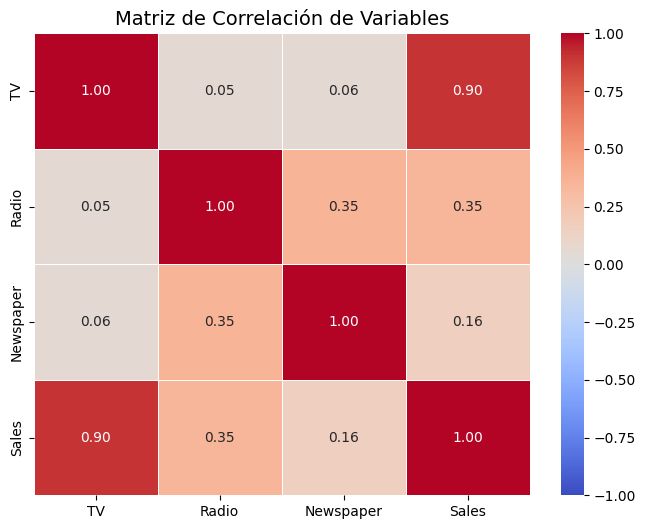

In [258]:
# Calcula la matriz de correlación
correlation_matrix = df[['TV', 'Radio', 'Newspaper', 'Sales']].corr()

# Visualízala con un heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Matriz de Correlación de Variables', fontsize=14)
plt.show()


*   **TV** es la variable con mayor correlación  con Sales; alcanzando una correlación positiva muy alta de 0.90.
* **Radio**presenta una correlación positiva moderada-baja de 0.35.
*  **Newspape**r muestra la correlación más débil con apenas 0.16.



## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

Valores de VIF:
   Predictor       VIF
0         TV  1.004611
1      Radio  1.144952
2  Newspaper  1.145187


/tmp/ipykernel_3111/2749510318.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Predictor', y='VIF', data=vif_data, palette='Blues_d')


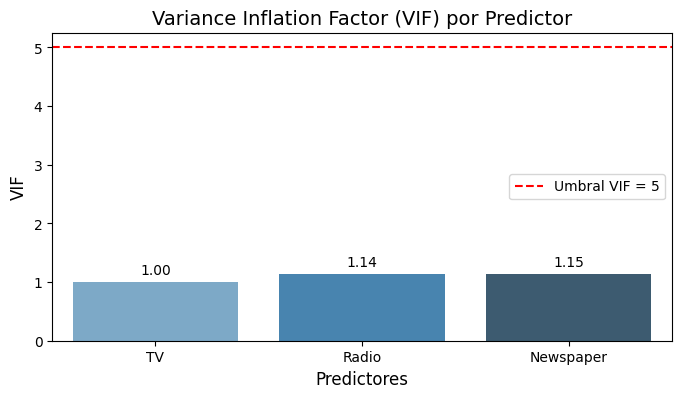

In [259]:
#Multicolinealidad
# Calcula el VIF (Variance Inflation Factor) para cada predictor
X = df[['TV', 'Radio', 'Newspaper']]

vif_data = pd.DataFrame()
vif_data['Predictor'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print("Valores de VIF:")
print(vif_data)

# Diagrama de barras para mostrar el VIF
plt.figure(figsize=(8, 4))
ax = sns.barplot(x='Predictor', y='VIF', data=vif_data, palette='Blues_d')

# línea de referencia para VIF = 5 o 10
plt.axhline(y=5, color='r', linestyle='--', label='Umbral VIF = 5')

plt.title('Variance Inflation Factor (VIF) por Predictor', fontsize=14)
plt.ylabel('VIF', fontsize=12)
plt.xlabel('Predictores', fontsize=12)
plt.legend()

# valores numéricos encima de cada barra
for bar in ax.patches:
    ax.annotate(f'{bar.get_height():.2f}',
                (bar.get_x() + bar.get_width() / 2., bar.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                textcoords='offset points')

plt.show()


Ninguna variable supera dichos umbrales. Los valores observados son de 1.00 para TV, 1.14 para Radio y 1.15 para Newspaper, los cuales se sitúan casi en el valor ideal (1.00) y muy por debajo del umbral de advertencia de 5.


**¿Qué implicaciones tiene esto para el modelo?**
Ausencia de multicolinealidad:


*   Indica que las variables independientes no están linealmente relacionadas entre sí de forma significativa.    
*   Coeficientes estables y confiables: Las estimaciones de los coeficientes de regresión ($\beta$) serán precisas, estables y contarán con errores estándar bajos, lo que permite evaluar el impacto individual de cada medio publicitario sobre Sales sin distorsiones.



## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [260]:
#Entrenamiento del Modelo (Todas las Variables Independientes)
# Definir las variables independientes (X) y la dependiente (y)
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# Separar en conjunto de entrenamiento y prueba (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entrenar el modelo de regresión lineal múltiple
model = LinearRegression()
model.fit(X_train, y_train)

# Muestrael intercepto y los coeficientes del modelo
print(f"Intercepto (Beta 0): {model.intercept_:.4f}\n")

print("Coeficientes por variable:")
for col, coef in zip(X.columns, model.coef_):
    print(f" - {col}: {coef:.4f}")



Intercepto (Beta 0): 4.7141

Coeficientes por variable:
 - TV: 0.0545
 - Radio: 0.1009
 - Newspaper: 0.0043


*   **Intercepto ($\beta_0 = 4.7141$):**
Representa el nivel base estimado de ventas cuando el presupuesto en todos los medios de comunicación (TV, Radio y Newspaper) es cero. Es decir, se esperarían ventas aproximadas de 4.71 unidades sin invertir nada en publicidad.

* **TV ($\beta_1 = 0.0545$):** Manteniendo constantes los demás medios, por cada 1,000 dólares adicionales invertidos en publicidad en televisión, las ventas se incrementan en promedio unas 54.5 unidades (o 0.0545 unidades por cada dólar).

*   **Radio ($\beta_2 = 0.1009$):** Manteniendo constantes los demás medios, por cada 1,000 dólares adicionales invertidos en radio, las ventas aumentan en promedio unas 100.9 unidades (o 0.1009 unidades por cada dólar). La radio demuestra la mayor tasa de retorno por unidad monetaria de gasto individual.

* **Newspaper ($\beta_3 = 0.0043$):** Manteniendo constantes los demás medios, por cada 1,000 dólares adicionales invertidos en periódicos, las ventas aumentan únicamente 4.3 unidades (o 0.0043 unidades por cada dólar). Su impacto directo en las ventas es prácticamente marginal.

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

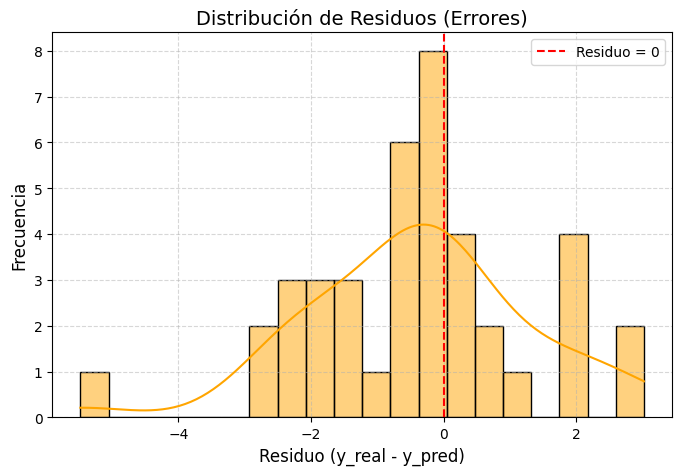

In [261]:
#Normalidad de los residuos

# Calcula los residuos usando el conjunto de entrenamiento
y_pred = model.predict(X_test)
residuos = y_test - y_pred

# Gráfica del histograma con KDE
plt.figure(figsize=(8, 5))
sns.histplot(residuos, kde=True, color='orange', bins=20)

plt.title('Distribución de Residuos (Errores)', fontsize=14)
plt.xlabel('Residuo (y_real - y_pred)', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.axvline(x=0, color='red', linestyle='--', label='Residuo = 0')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

**¿Los residuos parecen distribuirse normalmente?**



*  No porque hay Sesgo hacia la izquierda (asimetría): Aunque el pico más alto de frecuencia está cerca del cero, la distribución presenta una cola más larga hacia valores negativos (alrededor de $-5$). Por otro lado, existe multimodalidad en la zona de valores positivos (entre $1.5$ y $3$) se observa un segundo pico o acumulación de residuos, lo que aleja a la gráfica de la clásica forma de campana de Gauss perfectamente simétrica.




### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

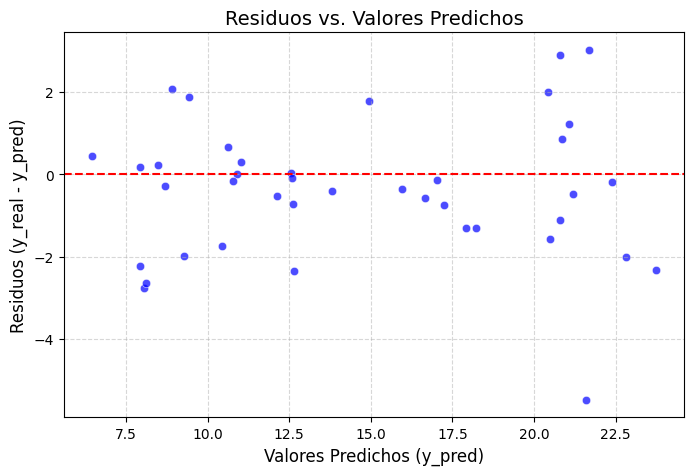

In [262]:
# Homocedasticidad

# Gráfica de los residuos contra los valores predichos
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuos, color='blue', alpha=0.7)

# Línea horizontal en residuo = 0 para referencia
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5)

plt.title('Residuos vs. Valores Predichos', fontsize=14)
plt.xlabel('Valores Predichos (y_pred)', fontsize=12)
plt.ylabel('Residuos (y_real - y_pred)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()



*   En general, sí presentan una dispersión relativamente aleatoria alrededor de la línea cero. No se observa un patrón claro en forma de embudo (que indicaría heterocedasticidad) ni una curvatura marcada en "U" o "U invertida" (que indicaría falta de linealidad).
*  Se observan **Outliers**: En la zona derecha (valores predichos superiores a 20) la dispersión vertical aumenta ligeramente e incluye un dato aislado con un residuo significativamente negativo (cercano a $-5.5$).



### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

<Figure size 800x600 with 0 Axes>

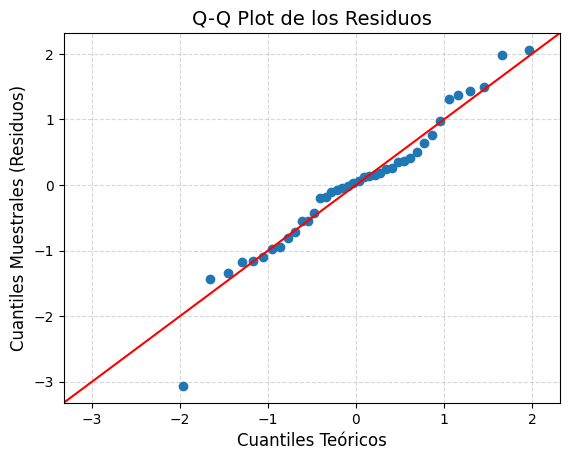

In [263]:
#Q-Q Plot
# Gráfica Q-Q Plot
plt.figure(figsize=(8, 6))
sm.qqplot(residuos, line='45', fit=True)

plt.title('Q-Q Plot de los Residuos', fontsize=14)
plt.xlabel('Cuantiles Teóricos', fontsize=12)
plt.ylabel('Cuantiles Muestrales (Residuos)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show();




*  **Cola izquierda (atípico inferior)**: Se observa un punto significativamente por debajo de la línea cerca del cuantil teórico -2 (valor muestra cercano a -3). Esto indica una ligera asimetría hacia la izquierda provocada por una predicción en la que el valor real fue sustancialmente menor que el predicho.

*  **Cola derecha**: En los cuantiles teóricos superiores a 1.5, los puntos se separan levemente hacia arriba.



### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [264]:
#Evaluación del Modelo
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MSE  (Error Cuadrático Medio): {mse:.4f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): {rmse:.4f}")
print(f"R²   (Coeficiente de Determinación): {r2:.4f}")

MSE  (Error Cuadrático Medio): 2.9078
RMSE (Raíz del Error Cuadrático Medio): 1.7052
R²   (Coeficiente de Determinación): 0.9059


*   **$R^2 = 0.9059$:**
El modelo explica aproximadamente el 90.59% de la variabilidad en las ventas (Sales) a partir de los presupuestos en TV, Radio y Newspaper, es decir un valor cercano a 1 indica un ajuste global muy sólido.

*   $\text{RMSE} = 1.7052$:
En promedio, las predicciones del modelo se desvían de los valores reales de ventas en aproximadamente 1.705 unidades. Al estar expresado en las mismas unidades que la variable objetivo.

* $\text{MSE} = 2.9078$ (Error cuadrático acumulado):
Refleja la media de los errores al cuadrado. Al penalizar con mayor peso las desviaciones grandes o valores atípicos, un valor relativamente bajo de 2.91 refuerza que los errores grandes son escasos en el conjunto de prueba.


### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.

3. ¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

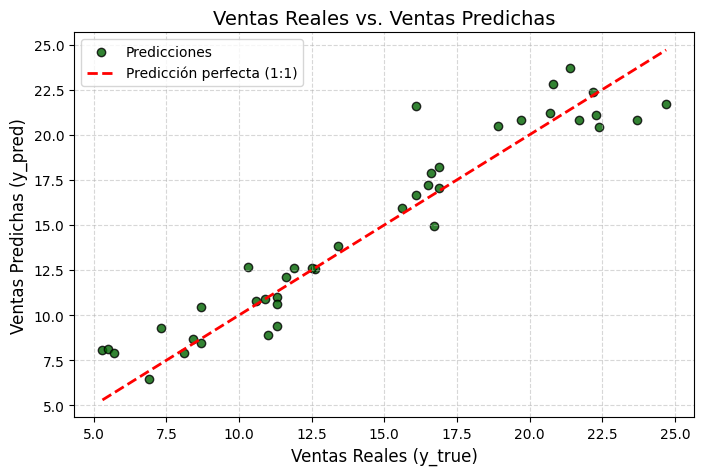

In [265]:
#Visualización de las Predicciones

# 1. Gráfica de Sales reales vs Sales predichas
plt.figure(figsize=(8, 5))

# Usa plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste
plt.scatter(y_test, y_pred, color='darkgreen', alpha=0.8, edgecolors='k', label='Predicciones')

# Línea de referencia diagonal (predicción perfecta: y_real = y_pred)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Predicción perfecta (1:1)')

plt.title('Ventas Reales vs. Ventas Predichas', fontsize=14)
plt.xlabel('Ventas Reales (y_true)', fontsize=12)
plt.ylabel('Ventas Predichas (y_pred)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

La dispersión estrecha alrededor de la diagonal confirma visualmente que el modelo posee una excelente capacidad predictiva y un ajuste lineal muy sólido porque los puntos se distribuyen de manera equilibrada tanto por encima como por debajo de la línea diagonal. Asimismo esto indica que las predicciones del modelo se aproximan con gran exactitud a los valores reales observados.

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [266]:
#P-values

# Definir variables independientes (X) el intercepto (Beta 0)
X = df[['TV', 'Radio', 'Newspaper']]
X_with_const = sm.add_constant(X)
y = df['Sales']

# Ajusta el modelo OLS (Ordinary Least Squares)
ols_model = sm.OLS(y, X_with_const).fit()

# Muestra el resumen estadístico completo
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        03:49:27   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0



*   **TV y Radio son estadísticamente significativas:** Al tener p-values menores a 0.05, se rechaza la hipótesis nula (beta = 0). Esto demuestra que la inversión en televisión y radio tiene un impacto real, medible y estadísticamente significativo sobre las ventas.

* **Newspaper NO es estadísticamente significativa:** Su p-value es de 0.954 (mucho mayor a 0.05). Esto significa que no hay suficiente evidencia estadística para afirmar que la publicidad en periódicos influya de forma directa en las ventas cuando se controlan las demás variables.



##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

De acuerdo a los resultado de la parte 3 no encontré valores con MULTICOLINEALIDAD pues ninguna variable supera dichos umbrales. Los valores observados son de 1.00 para TV, 1.14 para Radio y 1.15 para Newspaper, los cuales se sitúan casi en el valor ideal (1.00) y muy por debajo del umbral de advertencia de 5.

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

### 6.1 Entrenamiento del Modelo (SIN VARIABLES QUE NO MUESTRAN UNA RELACIÓN LINEAL)

1. Entrena un modelo de regresión lineal múltiple usando TV y Radio como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [267]:
#Entrenamiento del Modelo

# Definir las variables independientes (X) y la dependiente (y)
X = df[['TV', 'Radio']]
y = df['Sales']

# Separar en conjunto de entrenamiento y prueba (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entrenar el modelo de regresión lineal múltiple
model = LinearRegression()
model.fit(X_train, y_train)

# Muestrael intercepto y los coeficientes del modelo
print(f"Intercepto (Beta 0): {model.intercept_:.4f}\n")

print("Coeficientes por variable:")
for col, coef in zip(X.columns, model.coef_):
    print(f" - {col}: {coef:.4f}")

Intercepto (Beta 0): 4.7914

Coeficientes por variable:
 - TV: 0.0545
 - Radio: 0.1033


*   **Intercepto ($\beta_0 = 4.7914$):**
Representa el nivel base estimado de ventas cuando el presupuesto en ambos medios (TV y Radio) es cero. Es decir, se esperarían ventas aproximadas de 4.79 unidades sin invertir nada en publicidad en estos canales.  

*  **TV ($\beta_1 = 0.0545$):**
Manteniendo constante la inversión en Radio, por cada 1,000 dólares adicionales invertidos en publicidad en televisión, las ventas aumentan en promedio unas 54.5 unidades (o 0.0545 unidades por cada dólar).  

*  **Radio ($\beta_2 = 0.1033$):**
Manteniendo constante la inversión en TV, por cada 1,000 dólares adicionales invertidos en radio, las ventas se incrementan en promedio unas 103.3 unidades (o 0.1033 unidades por cada dólar).

### 6.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

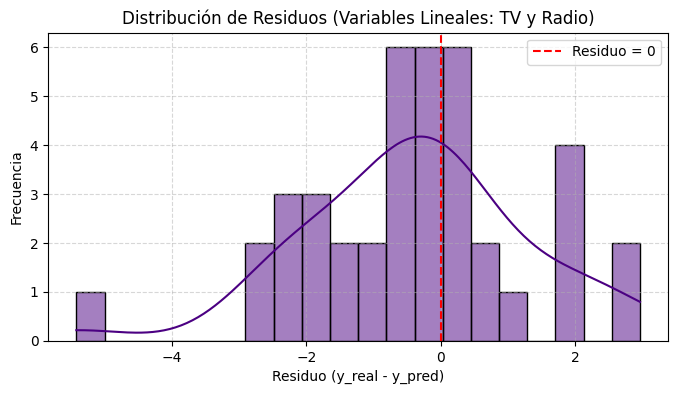

In [268]:
#Normalidad de los residuos

# Predicciones y residuos
y_pred = model_linear.predict(X_test)
residuos = y_test - y_pred

# Residuos: Histograma con KDE

plt.figure(figsize=(8, 4))
sns.histplot(residuos, kde=True, color='indigo', bins=20)
plt.axvline(x=0, color='red', linestyle='--', label='Residuo = 0')
plt.title('Distribución de Residuos (Variables Lineales: TV y Radio)', fontsize=12)
plt.xlabel('Residuo (y_real - y_pred)')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Observando la forma de la curva la distribución de residuos cumple de forma aceptable con el supuesto de normalidad.

# 6.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

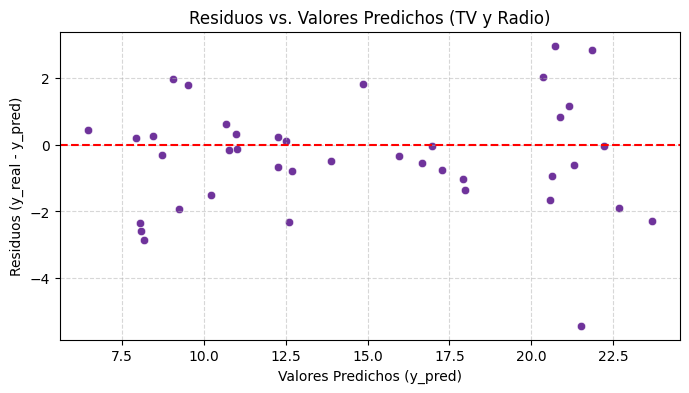

In [269]:
# Gráfica de Residuos vs. Valores Predichos
plt.figure(figsize=(8, 4))
sns.scatterplot(x=y_pred, y=residuos, color='indigo', alpha=0.8)
plt.axhline(y=0, color='red', linestyle='--')
plt.title('Residuos vs. Valores Predichos (TV y Radio)', fontsize=12)
plt.xlabel('Valores Predichos (y_pred)')
plt.ylabel('Residuos (y_real - y_pred)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()



*   en general se dispersan de forma aleatoria alrededor de la línea horizontal de referencia ($y = 0$). Los puntos se distribuyen de manera bastante equilibrada por encima y por debajo del cero a lo largo de la mayor parte del eje horizontal.

*  **Ligera variabilidad en extremos (Homocedasticidad)**: Aunque la dispersión vertical se mantiene acotada entre $-3$ y $2$ en casi todo el rango, para valores predichos altos (alrededor de $20$ a $22.5$) la dispersión vertical se amplía ligeramente e incluye un valor atípico con residuo negativo marcado ($\approx -5.5$).  



### 6.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

<Figure size 600x500 with 0 Axes>

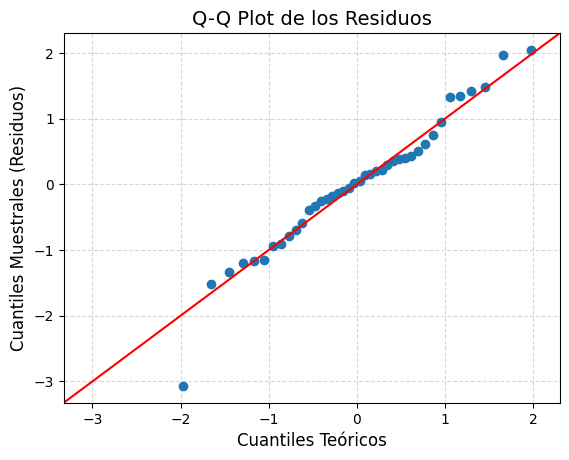

In [270]:
# Fráfica de Q-Q Plot

plt.figure(figsize=(6, 5))
sm.qqplot(residuos, line='45', fit=True)
plt.title('Q-Q Plot de los Residuos', fontsize=14)
plt.xlabel('Cuantiles Teóricos', fontsize=12)
plt.ylabel('Cuantiles Muestrales (Residuos)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show();


*  En el rango central (cuantiles teóricos entre -1.5 y 1.5), los puntos azules se alienen de manera casi perfecta a lo largo de la línea recta roja de 45°, la gran mayoría de los residuos del modelo siguen una distribución normal.

*  Existe un valor atípico (outlier) situado por debajo de la línea cerca del cuantil teórico -2 (con un valor muestral cercano a -3). Esto señala una leve asimetría negativa producida por un caso en el que la predicción sobreestimó notablemente el valor real.



### 6.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [271]:
# Métricas de Evaluación (MSE, RMSE, R²)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\nMétricas del Modelo Ajustado (TV y Radio):")
print(f" - MSE  (Error Cuadrático Medio)        : {mse:.4f}")
print(f" - RMSE (Raíz del Error Cuadrático Medio): {rmse:.4f}")
print(f" - R²   (Coeficiente de Determinación)   : {r2:.4f}")


Métricas del Modelo Ajustado (TV y Radio):
 - MSE  (Error Cuadrático Medio)        : 2.8466
 - RMSE (Raíz del Error Cuadrático Medio): 1.6872
 - R²   (Coeficiente de Determinación)   : 0.9079




* **$R^2 = 0.9079$ (Gran potencia explicativa):**
El modelo ajustado logra explicar el 90.79% de la variabilidad en las ventas (Sales) utilizando únicamente los presupuestos de televisión y radio. Esto demuestra que, incluso tras haber eliminado la variable Newspaper, el rendimiento global mejoró ligeramente respecto al modelo inicial ($R^2$ anterior $\approx 0.9059$

*  **$\text{RMSE} = 1.6872$ (Menor error típico):**
En promedio, las predicciones del modelo depurado se desvían de los valores reales de ventas en solo 1.6872 unidades. Al ser menor que el RMSE del modelo completo ($1.7052$), confirma que al retirar el ruido de Newspaper se ganó precisión en la predicción.

* **$\text{MSE} = 2.8466$ (Disminución del error cuadrático acumulado):**
Refleja un valor inferior al del modelo inicial ($2.9078$), lo que confirma que las penalizaciones por errores grandes se han reducido y los residuos se concentran más cerca del cero.


### 6.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.

3. ¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

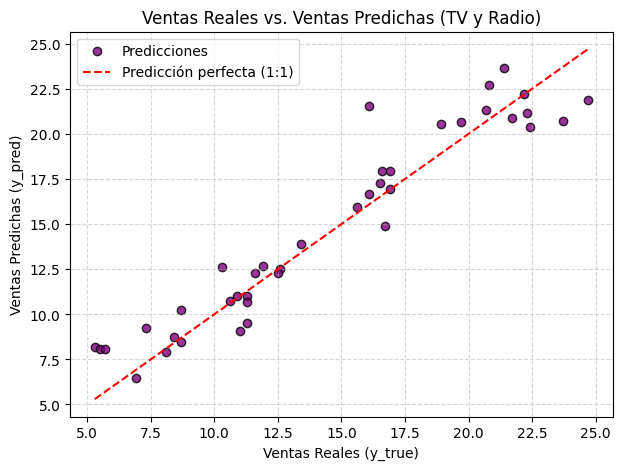

In [272]:
# Gráfico de Sales Reales vs. Sales Predichas

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color='purple', alpha=0.8, edgecolors='k', label='Predicciones')
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Predicción perfecta (1:1)')
plt.title('Ventas Reales vs. Ventas Predichas (TV y Radio)', fontsize=12)
plt.xlabel('Ventas Reales (y_true)')
plt.ylabel('Ventas Predichas (y_pred)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()



* La gran mayoría de los puntos morados se agrupan estrechamente a lo largo de la línea diagonal roja discontinua ($y_{pred} = y_{true}$). Esto confirma visualmente la alta precisión del modelo depurado ($R^2 \approx 0.9079$), mostrando que las predicciones se aproximan casi perfectamente a las ventas reales observadas.   Distribución simétrica de los errores (Sin sesgo global):

*  Los datos se reparten de forma equilibrada por encima y por debajo de la línea de predicción perfecta:Puntos sobre la línea: El modelo sobreestima levemente el valor real de ventas.Puntos bajo la línea: El modelo subestima levemente las ventas.





### 6.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [273]:
#P-values

# 7. Resumen OLS con Statsmodels (p-values)
X_const = sm.add_constant(X_linear)
ols_model_linear = sm.OLS(y, X_const).fit()
print("\nResumen OLS del Modelo (TV y Radio):")
print(ols_model_linear.summary())


Resumen OLS del Modelo (TV y Radio):
                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     912.7
Date:                Sat, 31 Oct 2026   Prob (F-statistic):          2.39e-100
Time:                        03:49:28   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             772.7
Df Residuals:                     197   BIC:                             782.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         



*   **Modelo validado y optimizado:** A diferencia del modelo inicial, ya no hay variables irrelevantes o de ruido (como Newspaper), lo que garantiza que todos los predictores incluidos aportan significativamente al poder explicativo del modelo ($R^2 = 0.903$, $F = 912.7$).

* : Todas las variables conservadas en este modelo reducido son altamente significativas a cualquier nivel habitual de significancia ($\alpha = 0.05, 0.01$ o $0.001$).



##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?



*   El mejor modelo fue el tercero porque contempla únicamente TV y Radio como predictores. LA diferencia fue porque **el modelo completo con las 3 variables** obtuvo un $R^2$ de $0.9059$ (o 0.903 en OLS), mientras que al eliminar Newspaper el $R^2$ se mantuvo prácticamente idéntico (0.90).

*  El atributo con mayor impacto global en el volumen de ventas es **TV**:
Correlación directa: Presenta una correlación lineal extremadamente alta con Sales (0.90).
Cuenta con el estadístico $t$ más elevado ($t = 39.592$) y el menor error estándar, demostrando ser la variable predictora más sólida y consistente para explicar el comportamiento de las ventas.
